updated on 25.2.2026 14:33 by xint. Debugged. Changed the look of the graph\
updated on 03.March.2026 16:13 by xint. Assign the aesthetics

## Inputs from you

In [18]:
treatments = ['control', 'ZIP']
colors = ['tab:blue', 'tab:orange']
# Check the names of colors in python here: https://matplotlib.org/stable/gallery/color/named_colors.html
labels = ['Control', 'ZIP']

to_save = 1
format_to_save = 'svg'
error_bar = 'sem' #  'sem' () or 'std' ()

## Import the data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.size'] = 8
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['pdf.fonttype'] = 42

mpl.rcParams['axes.linewidth'] = 0.5
mpl.rcParams['xtick.major.width'] = 0.5
mpl.rcParams['ytick.major.width'] = 0.5
mpl.rcParams['xtick.minor.width'] = 0.5
mpl.rcParams['ytick.minor.width'] = 0.5
mpl.rcParams['xtick.major.size'] = 2.5
mpl.rcParams['ytick.major.size'] = 2.5

mpl.rcParams['xtick.labelsize'] = 8
mpl.rcParams['ytick.labelsize'] = 8

treatments_data = [pd.read_excel(treatment +'/' + treatment + "___v_y_data_all.xlsx") for treatment in treatments]

## Plot the figure

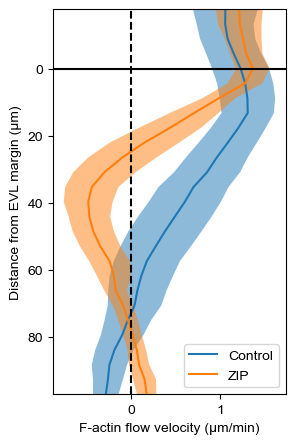

In [20]:
fig, ax = plt.subplots(figsize = [3,5])

for treatment_data, color, label in zip(treatments_data, colors, labels):

    v_avg = treatment_data['average']
    error_to_use = treatment_data[error_bar]
    y = treatment_data['y axis (um)']
    
    ax.plot(v_avg, y, c = color, label=label)
    ax.fill_betweenx(y = y,
                    x1 = v_avg - error_to_use,
                    x2 = v_avg + error_to_use,
                    alpha = 0.5, color = color, edgecolor = None)

ax.axhline(y = 0, color = 'black', ls = '-')
ax.axvline(x = 0, color = 'black', ls = '--')
ax.invert_yaxis()
ax.set_ylim(y.max(), y.min())
ax.set_xlabel('F-actin flow velocity (\u03BCm/min)')
ax.set_ylabel('Distance from EVL margin (\u03BCm)')
plt.legend()

if to_save:
    plt.savefig('v-y_plot_everything__with_' + error_bar+ '.' + format_to_save)
else:
    plt.show()